In [1]:
import h5py
import pyvista as pv
import numpy as np 
from scipy.interpolate import RegularGridInterpolator
import matplotlib.pyplot as plt 
import sys,os,glob,re
from IPython.display import Image as ipImage
from PIL import Image
import imageio
from scipy.ndimage import zoom
from skimage.transform import resize
from tqdm import tqdm

/usr/lib/python3/dist-packages/paramiko/transport.py:237: CryptographyDeprecationWarning: Blowfish has been deprecated and will be removed in a future release
  "class": algorithms.Blowfish,


In [2]:
def fetchFiles(path,keyword_in=None,keyword_out=None,sort=True):
    """
    Fetches files from a given path, optionally filtering them by inclusion or exclusion keywords,
    and sorts them in natural order if specified.
    
    Parameters:
    - path: The directory path where to search for files.
    - keyword_in: Optional list of keywords to include files. Only files containing any of these keywords will be included.
    - keyword_out: Optional list of keywords to exclude files. Any file containing any of these keywords will be excluded.
    - sort: Boolean indicating whether the returned file list should be sorted in natural order. Defaults to True.
    
    Returns:
    - List of file paths, filtered and sorted according to the specified criteria.
    """

    # Helper function to convert text to integers if possible,
    # which helps in sorting files naturally.
    def atoi(text):
        return int(text) if text.isdigit() else text

    # Split file names into parts that are integers or non-integers,
    # and convert integers to actual integers for natural sorting.
    def natural_keys(text):
        return [ atoi(c) for c in re.split('(\d+)',text) ]

    # Use glob to find all files matching the path pattern.
    files=glob.glob(path)

    # If inclusion keywords are specified, filter the files to include
    # only those containing any of the inclusion keywords.
    if keyword_in:
        keywordFilter=keyword_in
        files = [sent for sent in files
            if any(word in sent for word in keywordFilter)]

    # If exclusion keywords are specified, filter the files to exclude
    # those containing any of the exclusion keywords.
    if keyword_out:
        keywordFilter=keyword_out
        files = [sent for sent in files
            if not any(word in sent for word in keywordFilter)]

    # If sorting is enabled, sort the files using the natural keys method,
    # which considers numerical values for sorting parts of the file names.
    if sort:
        files.sort(key=natural_keys)
        return files
    else:
        return files

In [3]:
# Loop through files matching a pattern (eg. h5 files containing "data_LR_")
# fetched by the fetchFiles function. `volume_index` is the index of each file,
# and `target` is the file path.
base_path = './h0078/'
num_frames = 20
for volume_index,target in enumerate(fetchFiles(base_path + '*',['data_LR_'])):
    # Open the current h5 file in read mode.
    data = h5py.File(target,'r')
    
    # Store velocity encoding values in a list for further use.
    venc = [data['venc_u'][...],data['venc_v'][...],data['venc_w'][...]]

    # Close the current h5 file to free resources.
    data.close()   

for volume_index,target in enumerate(fetchFiles(base_path + '*',['data_up_orig_'])):
    data = h5py.File(target,'r')
    if volume_index == 0:
        # Initialize high-resolution data arrays for the first file.
        us_o = np.squeeze(data['u'][...])[...,np.newaxis]
        vs_o = np.squeeze(data['v'][...])[...,np.newaxis]
        ws_o = np.squeeze(data['w'][...])[...,np.newaxis]
    else:
        # Concatenate new data volumes to the existing arrays for subsequent files.
        us_o = np.concatenate((us_o,np.squeeze(data['u'][...])[...,np.newaxis]),axis=-1)
        vs_o = np.concatenate((vs_o,np.squeeze(data['v'][...])[...,np.newaxis]),axis=-1)
        ws_o = np.concatenate((ws_o,np.squeeze(data['w'][...])[...,np.newaxis]),axis=-1)
        
    # Close the current h5 file to free resources.
    data.close()   

for volume_index,target in enumerate(fetchFiles(base_path + '*',['data_no_overfit_'])):
    data = h5py.File(target,'r')
    if volume_index == 0:
        # Initialize high-resolution data arrays for the first file.
        us = np.squeeze(data['u'][...])[...,np.newaxis]
        vs = np.squeeze(data['v'][...])[...,np.newaxis]
        ws = np.squeeze(data['w'][...])[...,np.newaxis]
    else:
        # Concatenate new data volumes to the existing arrays for subsequent files.
        us = np.concatenate((us,np.squeeze(data['u'][...])[...,np.newaxis]),axis=-1)
        vs = np.concatenate((vs,np.squeeze(data['v'][...])[...,np.newaxis]),axis=-1)
        ws = np.concatenate((ws,np.squeeze(data['w'][...])[...,np.newaxis]),axis=-1)
        
    # Close the current h5 file to free resources.
    data.close()  

for volume_index,target in enumerate(fetchFiles(base_path + '*',['data_zero_filling_'])):
    data = h5py.File(target,'r')
    if volume_index == 0:
        # Initialize high-resolution data arrays for the first file.
        us_zero = np.squeeze(data['u'][...])[...,np.newaxis]
        vs_zero = np.squeeze(data['v'][...])[...,np.newaxis]
        ws_zero = np.squeeze(data['w'][...])[...,np.newaxis]
    else:
        # Concatenate new data volumes to the existing arrays for subsequent files.
        us_zero = np.concatenate((us_zero,np.squeeze(data['u'][...])[...,np.newaxis]),axis=-1)
        vs_zero = np.concatenate((vs_zero,np.squeeze(data['v'][...])[...,np.newaxis]),axis=-1)
        ws_zero = np.concatenate((ws_zero,np.squeeze(data['w'][...])[...,np.newaxis]),axis=-1)
        
    # Close the current h5 file to free resources.
    data.close() 

for volume_index,target in enumerate(fetchFiles(base_path + '*',['data_linear_'])):
    data = h5py.File(target,'r')
    if volume_index == 0:
        # Initialize high-resolution data arrays for the first file.
        us_linear = np.squeeze(data['u'][...])[...,np.newaxis]
        vs_linear = np.squeeze(data['v'][...])[...,np.newaxis]
        ws_linear = np.squeeze(data['w'][...])[...,np.newaxis]
    else:
        # Concatenate new data volumes to the existing arrays for subsequent files.
        us_linear = np.concatenate((us_linear,np.squeeze(data['u'][...])[...,np.newaxis]),axis=-1)
        vs_linear = np.concatenate((vs_linear,np.squeeze(data['v'][...])[...,np.newaxis]),axis=-1)
        ws_linear = np.concatenate((ws_linear,np.squeeze(data['w'][...])[...,np.newaxis]),axis=-1)
        
    # Close the current h5 file to free resources.
    data.close()   

for volume_index,target in enumerate(fetchFiles(base_path + '*',['data_cubic_'])):
    data = h5py.File(target,'r')
    if volume_index == 0:
        # Initialize high-resolution data arrays for the first file.
        us_cubic = np.squeeze(data['u'][...])[...,np.newaxis]
        vs_cubic = np.squeeze(data['v'][...])[...,np.newaxis]
        ws_cubic = np.squeeze(data['w'][...])[...,np.newaxis]
    else:
        # Concatenate new data volumes to the existing arrays for subsequent files.
        us_cubic = np.concatenate((us_cubic,np.squeeze(data['u'][...])[...,np.newaxis]),axis=-1)
        vs_cubic = np.concatenate((vs_cubic,np.squeeze(data['v'][...])[...,np.newaxis]),axis=-1)
        ws_cubic = np.concatenate((ws_cubic,np.squeeze(data['w'][...])[...,np.newaxis]),axis=-1)
        
    # Close the current h5 file to free resources.
    data.close()   

for volume_index,target in enumerate(fetchFiles(base_path + '*',['data_HR_'])):
    data = h5py.File(target,'r')
    if volume_index == 0:
        # Initialize high-resolution data arrays for the first file.
        ugt = np.squeeze(data['u'][...])[...,np.newaxis]
        vgt = np.squeeze(data['v'][...])[...,np.newaxis]
        wgt = np.squeeze(data['w'][...])[...,np.newaxis]
        mask = np.squeeze(data['mask'][...])[...,np.newaxis]
    else:
        # Concatenate new data volumes to the existing arrays for subsequent files.
        ugt = np.concatenate((ugt,np.squeeze(data['u'][...])[...,np.newaxis]),axis=-1)
        vgt = np.concatenate((vgt,np.squeeze(data['v'][...])[...,np.newaxis]),axis=-1)
        wgt = np.concatenate((wgt,np.squeeze(data['w'][...])[...,np.newaxis]),axis=-1)
        mask = np.concatenate((mask,np.squeeze(data['mask'][...])[...,np.newaxis]),axis=-1)
        
    # Close the current h5 file to free resources.
    data.close()   


In [4]:
print("max u ", np.max(us))
print("max v ", np.max(vs))
print("max w ", np.max(ws))

print("max u_gt ", np.max(ugt))
print("max v_gt ", np.max(vgt))
print("max w_gt ", np.max(wgt))

max u  2.2071815
max v  0.66511977
max w  0.988852
max u_gt  2.123
max v_gt  0.6953
max w_gt  1.002


In [5]:
# add a new axis to the data
us = us[np.newaxis,...]
vs = vs[np.newaxis,...]
ws = ws[np.newaxis,...]

ugt = ugt[np.newaxis,...]
vgt = vgt[np.newaxis,...]
wgt = wgt[np.newaxis,...]

us_o = us_o[np.newaxis,...]
vs_o = vs_o[np.newaxis,...]
ws_o = ws_o[np.newaxis,...]

us_zero = us_zero[np.newaxis,...]
vs_zero = vs_zero[np.newaxis,...]
ws_zero = ws_zero[np.newaxis,...]

us_linear = us_linear[np.newaxis,...]
vs_linear = vs_linear[np.newaxis,...]
ws_linear = ws_linear[np.newaxis,...]

us_cubic = us_cubic[np.newaxis,...]
vs_cubic = vs_cubic[np.newaxis,...]
ws_cubic = ws_cubic[np.newaxis,...]

In [6]:
target = np.concatenate((us,vs,ws),axis=0)
target_o = np.concatenate((us_o,vs_o,ws_o),axis=0)
target_zero = np.concatenate((us_zero,vs_zero,ws_zero),axis=0)
target_linear = np.concatenate((us_linear,vs_linear,ws_linear),axis=0)
target_cubic = np.concatenate((us_cubic,vs_cubic,ws_cubic),axis=0)
target_gt = np.concatenate((ugt,vgt,wgt),axis=0)
print("Upsampled shape: ", target.shape)
print("Ground truth shape: ", target_gt.shape)

Upsampled shape:  (3, 214, 66, 46, 20)
Ground truth shape:  (3, 217, 67, 47, 20)


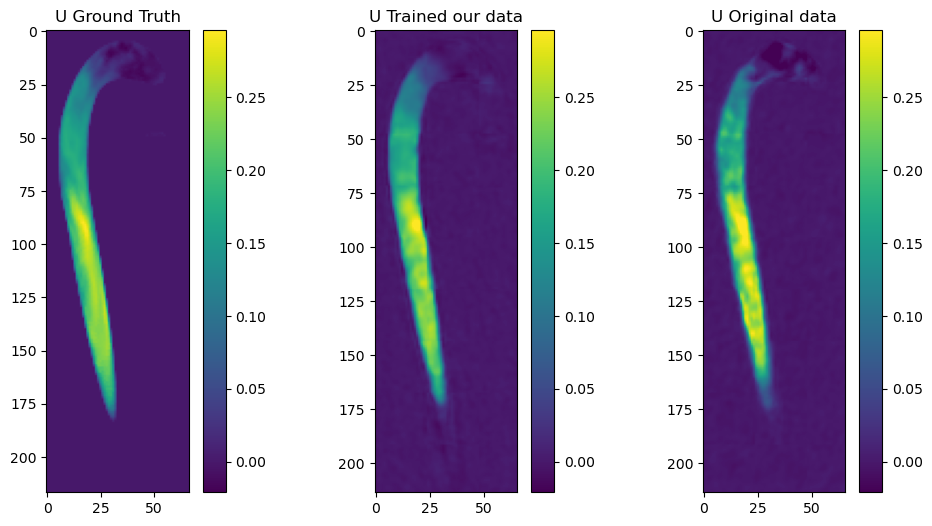

In [7]:
#visualize a slice of ugt and us with matplotlib
slice_index = 20

# Create a figure with two subplots.
fig,axs = plt.subplots(1,3,figsize=(12,6))

max_v = np.max(target_gt[0,...,slice_index,1])
min_v = np.min(target_gt[0,...,slice_index,1])

# Plot the slice of the ground truth data.
axs[0].imshow(target_gt[0,...,slice_index,1],cmap='viridis', vmin=min_v, vmax=max_v)

# Plot the slice of the upsampled data.
axs[1].imshow(target[0,...,slice_index,1],cmap='viridis', vmin=min_v, vmax=max_v)

axs[2].imshow(target_o[0,...,slice_index,1],cmap='viridis', vmin=min_v, vmax=max_v)



# Set titles for the subplots.
axs[0].set_title('U Ground Truth')
axs[1].set_title('U Trained our data')
axs[2].set_title('U Original data')

#add color bars
fig.colorbar(axs[0].imshow(target_gt[0,...,slice_index,1],cmap='viridis',vmin=min_v, vmax=max_v), ax=axs[0])
fig.colorbar(axs[1].imshow(target[0,...,slice_index,1],cmap='viridis',vmin=min_v, vmax=max_v), ax=axs[1])
fig.colorbar(axs[2].imshow(target_o[0,...,slice_index,1],cmap='viridis',vmin=min_v, vmax=max_v), ax=axs[2])

# Display the figure.
plt.show()

In [8]:
print("Before resize target shape: ", target.shape)
print("Target ground truth shape: ", target_gt.shape)
#resize like this but for every frame in the dataset separately
resized_target = np.zeros(target_gt.shape)
resized_target_o = np.zeros(target_gt.shape)
resized_target_zero = np.zeros(target_gt.shape)
resized_target_linear = np.zeros(target_gt.shape)
resized_target_cubic = np.zeros(target_gt.shape)

for i in tqdm(range(num_frames)):
    resized_target[...,i] = resize(target[...,i], target_gt[...,i].shape, order=1, mode='constant', anti_aliasing=True)
    resized_target_o[...,i] = resize(target_o[...,i], target_gt[...,i].shape, order=1, mode='constant', anti_aliasing=True)
    resized_target_zero[...,i] = resize(target_zero[...,i], target_gt[...,i].shape, order=1, mode='constant', anti_aliasing=True)
    resized_target_linear[...,i] = resize(target_linear[...,i], target_gt[...,i].shape, order=1, mode='constant', anti_aliasing=True)
    resized_target_cubic[...,i] = resize(target_cubic[...,i], target_gt[...,i].shape, order=1, mode='constant', anti_aliasing=True)

print("Resized target shape: ", resized_target.shape, "    Target ground truth shape: ", target_gt.shape)

Before resize target shape:  (3, 214, 66, 46, 20)
Target ground truth shape:  (3, 217, 67, 47, 20)


100%|██████████| 20/20 [00:41<00:00,  2.06s/it]

Resized target shape:  (3, 217, 67, 47, 20)     Target ground truth shape:  (3, 217, 67, 47, 20)


In [9]:
binary_mask = np.zeros(mask.shape,dtype=bool)
binary_mask[mask>0.5] = True
binary_mask_non_fluid = np.logical_not(binary_mask)

masked_target = resized_target[:,binary_mask]
masked_target_o = resized_target_o[:,binary_mask]
masked_target_zero = resized_target_zero[:,binary_mask]
masked_target_linear = resized_target_linear[:,binary_mask]
masked_target_cubic = resized_target_cubic[:,binary_mask]
nf_masked_target = resized_target[:,binary_mask_non_fluid]
nf_masked_target_o = resized_target_o[:,binary_mask_non_fluid]
nf_masked_target_zero = resized_target_zero[:,binary_mask_non_fluid]
nf_masked_target_linear = resized_target_linear[:,binary_mask_non_fluid]
nf_masked_target_cubic = resized_target_cubic[:,binary_mask_non_fluid]

masked_target_gt = target_gt[:,binary_mask]
nf_masked_target_gt = target_gt[:,binary_mask_non_fluid]

In [10]:
def directional_error(vectors_a, vectors_b):
    # Dot product between pairs of vectors
    dot_product = np.abs(np.einsum('ij,ij->j', vectors_a, vectors_b))

    # Norm (magnitude) of each vector
    norm_a = np.linalg.norm(vectors_a, axis=0) + 1e-6
    norm_b = np.linalg.norm(vectors_b, axis=0) + 1e-6
    return np.mean(1-dot_product/norm_a/norm_b)*100
def vectorial_rmse(vectors_a, vectors_b):
    # Vectorial difference
    diff = np.mean(np.linalg.norm(vectors_a-vectors_b,axis=0)**2)
    #Norm (magnitude) of reference target (here: vectors_b)
    norm = np.mean(np.linalg.norm(vectors_b,axis=0)**2) + 1e-6
    
    return np.sqrt(diff/norm)*100
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# Metric analysis for whole geometry our data

In [11]:
print("Fluid region:\n")
dir_error = directional_error(masked_target.reshape(3,-1),masked_target_gt.reshape(3,-1))
vec_rmse = vectorial_rmse(masked_target.reshape(3,-1),masked_target_gt.reshape(3,-1))
rmse_val = rmse(masked_target,masked_target_gt)
print(f"Directional error: {dir_error:.2f}%")
print(f"Vectorial RMSE: {vec_rmse:.2f}%")
print(f"RMSE: {rmse_val:.3f}")

Fluid region:

Directional error: 4.34%
Vectorial RMSE: 21.60%
RMSE: 0.082


In [12]:
print("Fluid + non fluid region:\n")
dir_error = directional_error(resized_target.reshape(3,-1),target_gt.reshape(3,-1))
vec_rmse = vectorial_rmse(resized_target.reshape(3,-1),target_gt.reshape(3,-1))
rmse_val = rmse(resized_target,target_gt)
print(f"Directional error: {dir_error:.2f}%")
print(f"Vectorial RMSE: {vec_rmse:.2f}%")
print(f"RMSE: {rmse_val:.3f}")

Fluid + non fluid region:



Directional error: 92.13%
Vectorial RMSE: 27.50%
RMSE: 0.030


In [13]:
print("Non fluid region:\n")
dir_error = directional_error(nf_masked_target.reshape(3,-1),nf_masked_target_gt.reshape(3,-1))
vec_rmse = vectorial_rmse(nf_masked_target.reshape(3,-1),nf_masked_target_gt.reshape(3,-1))
rmse_val = rmse(nf_masked_target,nf_masked_target_gt)
print(f"Directional error: {dir_error:.2f}%")
print(f"Vectorial RMSE: {vec_rmse:.2f}%")
print(f"RMSE: {rmse_val:.3f}")

Non fluid region:

Directional error: 100.00%
Vectorial RMSE: 3340.58%
RMSE: 0.019


# Metric analysis for whole geometry Ferdian data

In [14]:
print("Fluid region:\n")
dir_error = directional_error(masked_target_o.reshape(3,-1),masked_target_gt.reshape(3,-1))
vec_rmse = vectorial_rmse(masked_target_o.reshape(3,-1),masked_target_gt.reshape(3,-1))
rmse_val = rmse(masked_target_o,masked_target_gt)
print(f"Directional error: {dir_error:.2f}%")
print(f"Vectorial RMSE: {vec_rmse:.2f}%")
print(f"RMSE: {rmse_val:.3f}")

Fluid region:

Directional error: 4.76%
Vectorial RMSE: 21.51%
RMSE: 0.081


In [15]:
print("Fluid + non fluid region:\n")
dir_error = directional_error(resized_target_o.reshape(3,-1),target_gt.reshape(3,-1))
vec_rmse = vectorial_rmse(resized_target_o.reshape(3,-1),target_gt.reshape(3,-1))
rmse_val = rmse(resized_target_o,target_gt)
print(f"Directional error: {dir_error:.2f}%")
print(f"Vectorial RMSE: {vec_rmse:.2f}%")
print(f"RMSE: {rmse_val:.3f}")

Fluid + non fluid region:

Directional error: 92.17%
Vectorial RMSE: 27.38%
RMSE: 0.030


In [16]:
print("Non fluid region:\n")
dir_error = directional_error(nf_masked_target_o.reshape(3,-1),nf_masked_target_gt.reshape(3,-1))
vec_rmse = vectorial_rmse(nf_masked_target_o.reshape(3,-1),nf_masked_target_gt.reshape(3,-1))
rmse_val = rmse(nf_masked_target_o,nf_masked_target_gt)
print(f"Directional error: {dir_error:.2f}%")
print(f"Vectorial RMSE: {vec_rmse:.2f}%")
print(f"RMSE: {rmse_val:.3f}")

Non fluid region:

Directional error: 100.00%
Vectorial RMSE: 3323.63%
RMSE: 0.019


# Metric analysis for each frame

In [17]:
# apply binary max to each frame of the array resized_target (214,66,46,20) the frame number is the last dimension
masked_target_list = []
masked_target_o_list = []
masked_target_zero_list = []
masked_target_linear_list = []
masked_target_cubic_list = []
masked_target_gt_list = []
for i in range(num_frames):
    masked_target_list.append(resized_target[:,binary_mask[...,i],i])
    masked_target_o_list.append(resized_target_o[:,binary_mask[...,i],i])
    masked_target_zero_list.append(resized_target_zero[:,binary_mask[...,i],i])
    masked_target_linear_list.append(resized_target_linear[:,binary_mask[...,i],i])
    masked_target_cubic_list.append(resized_target_cubic[:,binary_mask[...,i],i])
    masked_target_gt_list.append(target_gt[:,binary_mask[...,i],i])

In [18]:
norm_velocity = np.sqrt(np.sum(resized_target**2,axis=0))
norm_velocity_o = np.sqrt(np.sum(resized_target_o**2,axis=0))
norm_velocity_zero = np.sqrt(np.sum(resized_target_zero**2,axis=0))
norm_velocity_linear = np.sqrt(np.sum(resized_target_linear**2,axis=0))
norm_velocity_cubic = np.sqrt(np.sum(resized_target_cubic**2,axis=0))
norm_velocity_gt = np.sqrt(np.sum(target_gt**2,axis=0))

masked_norm_velocity_list = []
masked_norm_velocity_o_list = []
masked_norm_velocity_zero_list = []
masked_norm_velocity_linear_list = []
masked_norm_velocity_cubic_list = []
masked_norm_velocity_gt_list = []

for i in range(num_frames):
    masked_norm_velocity_list.append(norm_velocity[binary_mask[...,i],i])
    masked_norm_velocity_gt_list.append(norm_velocity_gt[binary_mask[...,i],i])
    masked_norm_velocity_o_list.append(norm_velocity_o[binary_mask[...,i],i])
    masked_norm_velocity_zero_list.append(norm_velocity_zero[binary_mask[...,i],i])
    masked_norm_velocity_linear_list.append(norm_velocity_linear[binary_mask[...,i],i])
    masked_norm_velocity_cubic_list.append(norm_velocity_cubic[binary_mask[...,i],i])

# compute the average velocity magnitude for each frame
average_velocity = []
average_velocity_gt = []
average_velocity_o = []
average_velocity_zero = []
average_velocity_linear = []
average_velocity_cubic = []
for i in range(num_frames):
    average_velocity.append(np.mean(masked_norm_velocity_list[i])*100)
    average_velocity_gt.append(np.mean(masked_norm_velocity_gt_list[i])*100)
    average_velocity_o.append(np.mean(masked_norm_velocity_o_list[i])*100)
    average_velocity_zero.append(np.mean(masked_norm_velocity_zero_list[i])*100)
    average_velocity_linear.append(np.mean(masked_norm_velocity_linear_list[i])*100)
    average_velocity_cubic.append(np.mean(masked_norm_velocity_cubic_list[i])*100)

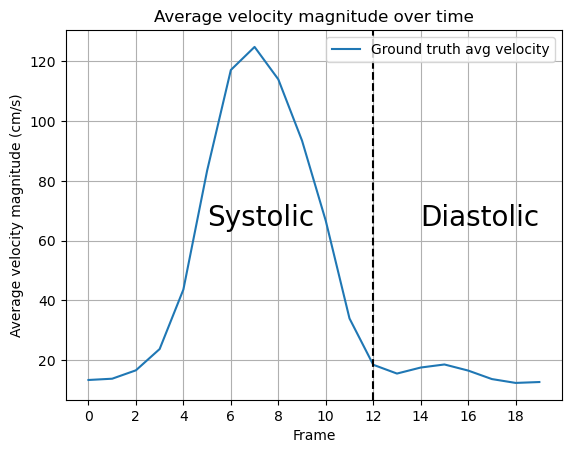

In [19]:
# plot the average velocity over time

#plt.plot(average_velocity, label='Our 4DFlowNet')
plt.plot(average_velocity_gt, label='Ground truth avg velocity')
# plt.plot(average_velocity_o, label='Original data')
# plt.plot(average_velocity_zero, label='Zero filling')
# plt.plot(average_velocity_linear, label='Linear interpolation')
# plt.plot(average_velocity_cubic, label='Cubic interpolation')

#write text on the plot
plt.text(14, 65, 'Diastolic', fontsize=20, style='normal')
plt.text(5, 65, 'Systolic', fontsize=20, style='normal')




plt.axvline(x=12, color='black', linestyle='--')
plt.xticks(np.arange(0, 20, 2))
plt.xlabel('Frame')
plt.ylabel('Average velocity magnitude (cm/s)')
plt.legend()
plt.title('Average velocity magnitude over time')
plt.grid()
plt.show()

In [20]:
# plot how the above metrics evolve over time

directional_error_list = []
directional_error_o_list = []
directional_error_zero_list = []
directional_error_linear_list = []
directional_error_cubic_list = []
vectorial_rmse_list = []
vectorial_rmse_o_list = []
rmse_list = []
rmse_o_list = []
for i in range(num_frames):
    directional_error_list.append(directional_error(masked_target_list[i], masked_target_gt_list[i]))
    directional_error_o_list.append(directional_error(masked_target_o_list[i], masked_target_gt_list[i]))
    directional_error_zero_list.append(directional_error(masked_target_zero_list[i], masked_target_gt_list[i]))
    directional_error_linear_list.append(directional_error(masked_target_linear_list[i], masked_target_gt_list[i]))
    directional_error_cubic_list.append(directional_error(masked_target_cubic_list[i], masked_target_gt_list[i]))
    vectorial_rmse_list.append(vectorial_rmse(masked_target_list[i], masked_target_gt_list[i]))
    vectorial_rmse_o_list.append(vectorial_rmse(masked_target_o_list[i], masked_target_gt_list[i]))
    rmse_list.append(rmse(masked_target_list[i], masked_target_gt_list[i]))
    rmse_o_list.append(rmse(masked_target_o_list[i], masked_target_gt_list[i]))

[17.327642472896617, 16.379693443138393, 13.885322669913458, 10.428080153891072, 6.373259769838216, 3.8622810405279235, 3.1828009686588437, 3.116656983868211, 3.485088423596503, 4.289377140576702, 6.382896140146604, 10.563943870536512, 15.541062860299071, 16.23809050969024, 13.745606564190108, 12.982454354591319, 14.690993618818608, 16.780460110458783, 18.023420349823894, 17.646457880244757]
[26.271780503301084, 25.318211973794856, 21.697163231382614, 15.91626833268472, 8.991310759686197, 5.384448151434981, 4.30992280564814, 4.069650720499072, 4.655432477330033, 5.725090095731302, 8.309168409234523, 14.109047365910596, 21.550270369537593, 23.56139049327713, 21.114584574756343, 20.32733304167193, 22.339913722375467, 25.531018602215312, 27.127251281121485, 26.607514049345397]


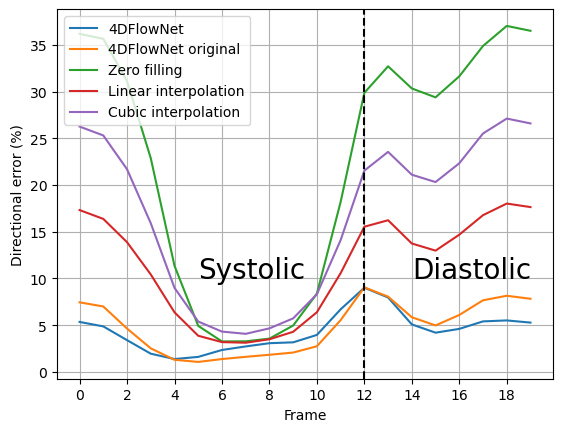

In [21]:
plt.plot(directional_error_list, label='4DFlowNet')
plt.plot(directional_error_o_list, label='4DFlowNet original')
plt.plot(directional_error_zero_list, label='Zero filling')
plt.plot(directional_error_linear_list, label='Linear interpolation')
plt.plot(directional_error_cubic_list, label='Cubic interpolation')
plt.text(14, 10, 'Diastolic', fontsize=20, style='normal')
plt.text(5, 10, 'Systolic', fontsize=20, style='normal')
print(directional_error_linear_list)
print(directional_error_cubic_list)




plt.axvline(x=12, color='black', linestyle='--')
plt.xticks(np.arange(0, 20, 2))
plt.xlabel('Frame')
plt.ylabel('Directional error (%)')
plt.grid()
plt.legend()
plt.show()

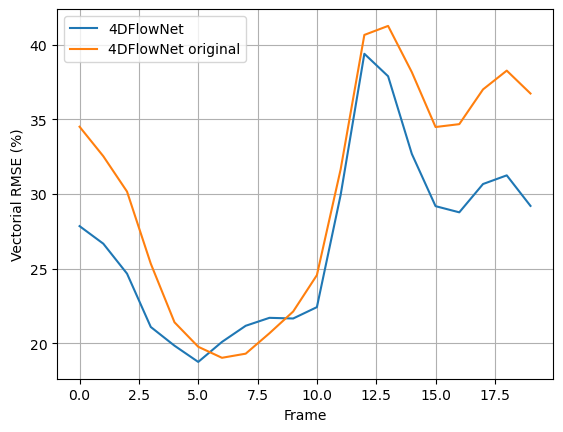

In [22]:
plt.plot(vectorial_rmse_list, label='4DFlowNet')
plt.plot(vectorial_rmse_o_list, label='4DFlowNet original')
plt.xlabel('Frame')
plt.ylabel('Vectorial RMSE (%)')
plt.grid()
plt.legend()
plt.show()

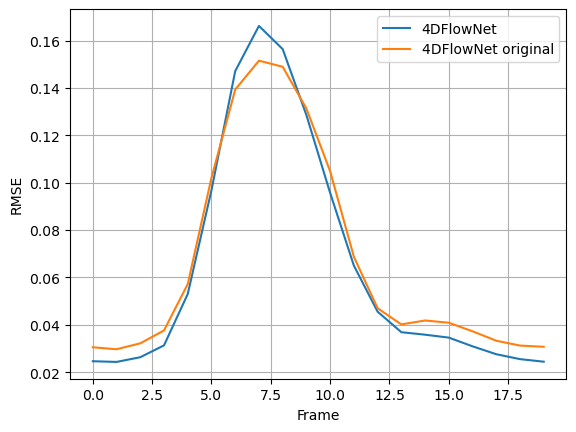

In [23]:
plt.plot(rmse_list, label='4DFlowNet')
plt.plot(rmse_o_list, label='4DFlowNet original')
plt.xlabel('Frame')
plt.ylabel('RMSE')
plt.grid()
plt.legend()
plt.show()